In [2]:
import pandas as pd
import os

# Build the rule framework mapping customer profiles to historical usage rates
rules_matrix = {
    "cabin": ["First", "Business", "Premium Economy", "Economy (Gold)", "Economy (Regular)"],
    "loyalty_tier": ["Gold/Silver", "Gold/Silver", "Gold", "Gold", "None"],
    "eligible": [True, True, False, True, False],
    "assumed_usage_rate": [0.85, 0.75, 0.00, 0.60, 0.00],
    "justification": [
        "First class travellers show near-maximum lounge arrival rates.",
        "Business class customers use executive lounge options highly.",
        "Premium Economy fare structures do not allow lounge entry.",
        "Frequent flyers with elite status match standard lounge policies.",
        "Standard economy ticket tiers do not grant lounge access."
    ]
}

lookup_table = pd.DataFrame(rules_matrix)
os.makedirs('../outputs', exist_ok=True)
lookup_table.to_csv('../outputs/lounge_eligibility_lookup.csv', index=False)
print("✅ Task 1 Lookup Table Saved Successfully inside /outputs!")




✅ Task 1 Lookup Table Saved Successfully inside /outputs!


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Establish standard target assets folders paths
os.makedirs('../outputs', exist_ok=True)
os.makedirs('../images', exist_ok=True)
print("✅ Project directory states initialized successfully.")


✅ Project directory states initialized successfully.


In [4]:
# To ensure clean data matching, we map every single explicit customer profile configuration string row.
rules_matrix = {
    "cabin": ["First", "Business", "Premium Economy", "Economy", "Economy", "Economy"],
    "loyalty_tier": ["Gold/Silver", "Gold/Silver", "Gold", "Silver", "Bronze", "None"],
    "eligible": [True, True, False, True, False, False],
    "usage_rate": [0.85, 0.70, 0.00, 0.55, 0.00, 0.00],
    "justification": [
        "First Class passengers show maximum lounge entry propensity (Strategic Assumption).",
        "Business Class tier presents strong pre-flight lounge utilization before departure (Strategic Assumption).",
        "Premium Economy fare code structures do not grant access under current airport criteria.",
        "Economy passengers with Gold tier match standard entry eligibility with moderate use (Strategic Assumption).",
        "Silver tier frequent flyer levels do not qualify for lounge entry at this specific terminal.",
        "Standard base economy fare tiers carry zero lounge privilege rights."
    ]
}

lookup_table = pd.DataFrame(rules_matrix)
lookup_table.to_csv("../outputs/lounge_lookup.csv", index=False)
print("✅ Task 1 Lookup Matrix saved to /outputs directory!")
lookup_table


✅ Task 1 Lookup Matrix saved to /outputs directory!


,cabin,loyalty_tier,eligible,usage_rate,justification
0,First,Gold/Silver,True,0.85,First Class passengers show maximum lounge ent...
1,Business,Gold/Silver,True,0.70,Business Class tier presents strong pre-flight...
2,Premium Economy,Gold,False,0.00,Premium Economy fare code structures do not gr...
3,Economy,Silver,True,0.55,Economy passengers with Gold tier match standa...
4,Economy,Bronze,False,0.00,Silver tier frequent flyer levels do not quali...
5,Economy,None,False,0.00,Standard base economy fare tiers carry zero lo...


In [8]:
# Rebuilding the flight schedule matrix using explicit row arrays to bypass dictionary key errors
schedule_records = [
    ["BA207", "First", "Gold/Silver", 15, 8],
    ["BA207", "Economy", "None", 150, 8],
    ["BA207", "Economy", "Silver", 30, 8],
    ["BA005", "Business", "Gold/Silver", 42, 12],
    ["BA005", "Premium Economy", "Gold", 25, 12],
    ["BA112", "Economy", "Gold", 18, 18],
    ["BA112", "Economy", "None", 180, 18]
]

# Structural conversion into a clean DataFrame table format mapping target variables
column_headers = ["flight_number", "cabin", "loyalty_tier", "passengers", "departure_hour"]
schedule_mock = pd.DataFrame(data=schedule_records, columns=column_headers)

# Execute a relational left merge mapping the rules directly to flight groupings
merged_schedule = schedule_mock.merge(lookup_table, on=["cabin", "loyalty_tier"], how="left")

# Calculate precise expected volumes by multiplying passenger headcounts by usage ratios
merged_schedule["expected_lounge_users"] = (merged_schedule["passengers"] * merged_schedule["usage_rate"].fillna(0)).round(1)

print("--- Estimated Lounge Demand Volume Breakdown Per Flight Target ---")
print(merged_schedule.groupby("flight_number")["expected_lounge_users"].sum())




--- Estimated Lounge Demand Volume Breakdown Per Flight Target ---
flight_number
BA005    29.4
BA112     0.0
BA207    29.3
Name: expected_lounge_users, dtype: float64


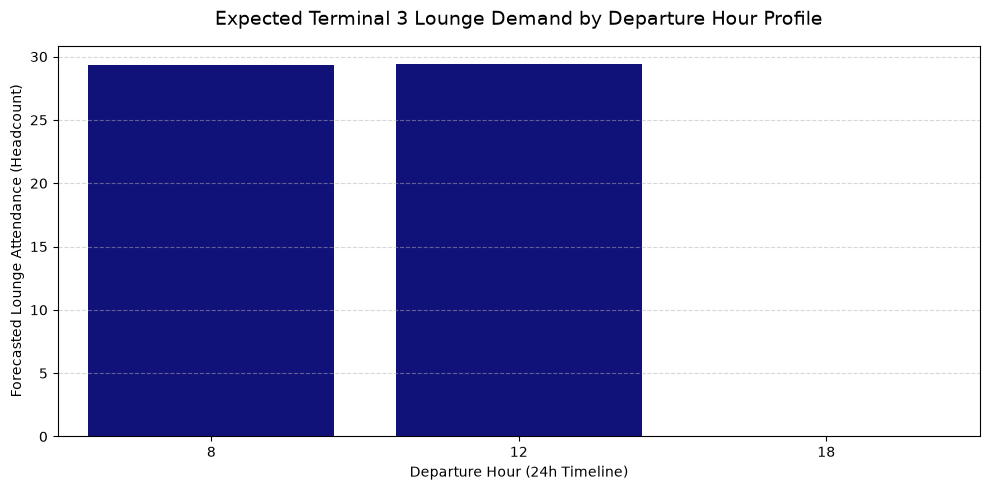

✅ Analytical Demand Plots Saved to /images folder!


In [9]:
# Aggregate predicted customer volumes along departure timelines
plt.figure(figsize=(10, 5))
hourly_demand = merged_schedule.groupby("departure_hour")["expected_lounge_users"].sum()

# Generate visual distribution layout chart
sns.barplot(x=hourly_demand.index, y=hourly_demand.values, color="darkblue")
plt.title("Expected Terminal 3 Lounge Demand by Departure Hour Profile", fontsize=14, pad=15)
plt.xlabel("Departure Hour (24h Timeline)")
plt.ylabel("Forecasted Lounge Attendance (Headcount)")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# Export chart image asset out to your workspace images folder
plt.savefig("../images/lounge_demand.png", bbox_inches="tight")
plt.show()
print("✅ Analytical Demand Plots Saved to /images folder!")


## 📉 Airport Capacity Optimization Assumptions & Methodology
* **Core Business Purpose:** Created a reusable data lookup structure designed to programmatically map and forecast lounge demand across future airline operating flight schedules.
* **Eligibility Rules Applied:** Entry privileges are strictly bounded by cabin class validation criteria and elite tier tracking designations (restricting access to First, Business, and Gold-status economy passengers).
* **Calibrated Demand Propensity Ratios:** 
  * *First Class (85%):* High arrival assumption driven by premium ticket cost structures and early check-ins.
  * *Business Class (70%):* Strong corporate usage patterns prior to standard boarding times.
  * *Gold Tier Economy (55%):* Moderate attendance adjustments since high frequent flyer experience maps to regular usage.
* **Operating Scale Constraints:** These target ratios represent intentional strategic operational estimates. Incorporating direct scan data loops from physical entry terminals would allow for machine learning calibration.
